# Paso 2 · Funciones de transferencia, polos y ceros (con Python)

Notebook del **Paso 2**. Dos hilos a la vez:

1. **Matemático**: sistema, ecuación diferencial, Laplace, $P(s)=Y(s)/U(s)$, polos, ceros y estabilidad.
2. **De programación**: clases y métodos, `np.roots`/`np.poly`, listas por comprensión, `scipy.signal` para *contrastar* nuestros cálculos, gráficos.

| Concepto matemático | Concepto de programación |
|---|---|
| ecuación diferencial | bucle de integración numérica (Euler) |
| $P(s)=N(s)/D(s)$ | clase `FuncionTransferencia` con `__call__` |
| polos y ceros | `np.roots`, `np.poly` |
| estable ⇔ polos con $\mathrm{Re}<0$ | `all(...)` sobre una lista |
| $P(j\omega)$ factor a factor | comprensión de listas, producto con `np.prod` |
| respuesta a una senoidal | `scipy.signal.lsim` como verificación |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

from scipy import signal

## 1. Un sistema: algo que transforma una entrada en una salida

Ejemplo mínimo: un depósito, un motor, un filtro... En todos, una **entrada** $u(t)$ produce una **salida** $y(t)$. El modelo más simple es de primer orden:

$$\dot y(t) = p\,y(t) + u(t)$$

con $p$ una constante. Si $u=0$ y partimos de $y(0)=1$, la solución es $y(t)=e^{pt}$: decae si $p<0$ y **explota** si $p>0$. Lo comprobamos **integrando numéricamente** (método de Euler: avanzar un paso pequeño $\Delta t$ siguiendo la pendiente).

p =   -1:  error máximo de Euler frente a e^(pt) = 0.0002
p =   -5:  error máximo de Euler frente a e^(pt) = 0.0009
p =  0.5:  error máximo de Euler frente a e^(pt) = 0.0017


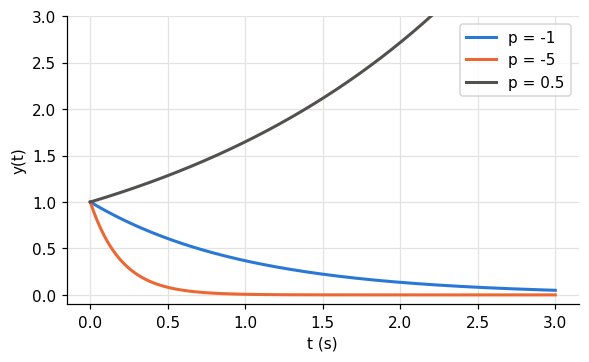

In [2]:
def euler_primer_orden(p, t_fin=3.0, dt=0.001, y0=1.0):
    """Integra y' = p*y con el método de Euler. Devuelve (t, y)."""
    n = int(t_fin / dt)
    t = np.linspace(0, t_fin, n + 1)
    y = np.empty(n + 1)
    y[0] = y0
    for k in range(n):                       # un bucle: cada paso usa el anterior
        y[k + 1] = y[k] + dt * (p * y[k])    # y_{k+1} = y_k + dt * y'_k
    return t, y

fig, ax = plt.subplots(figsize=(6, 3.4))
for p, col in [(-1, AZUL), (-5, NARANJA), (0.5, GRIS)]:
    t, y = euler_primer_orden(p, t_fin=3)
    ax.plot(t, y, color=col, lw=2, label=f"p = {p}")
    err = np.max(np.abs(y - np.exp(p * t)))            # comparamos con la solución exacta
    print(f"p = {p:>4}:  error máximo de Euler frente a e^(pt) = {err:.4f}")
ax.set_ylim(-0.1, 3); ax.set_xlabel("t (s)"); ax.set_ylabel("y(t)"); ax.legend()
plt.show()

**Qué hemos visto.** Un polo en $s=p$ negativo da una exponencial que decae (cuanto más a la izquierda, más rápido); uno positivo da una exponencial que crece. Eso es la **estabilidad**.

**Programación.** Un bucle `for` para integrar es lento pero muy claro. Más abajo usaremos `scipy.signal` para lo mismo en una línea y lo usaremos para **verificar** nuestras fórmulas.

## 2. La función de transferencia $P(s)=Y(s)/U(s)$

Aplicando la transformada de Laplace, derivar se convierte en multiplicar por $s$. La ecuación $\dot y=py+u$ pasa a $sY=pY+U$, es decir

$$P(s)=\frac{Y(s)}{U(s)}=\frac{1}{s-p}.$$

En general $P(s)=\dfrac{N(s)}{D(s)}$, cociente de polinomios en $s$. Guardamos los dos polinomios por sus **coeficientes** (de mayor a menor potencia) y creamos una **clase** que sabe evaluarse, dar sus polos y ceros y decir si es estable.

In [3]:
class FuncionTransferencia:
    """P(s) = k * prod(s - ceros) / prod(s - polos)."""

    def __init__(self, ceros, polos, k=1.0):
        self.ceros = np.array(ceros, dtype=complex)
        self.polos = np.array(polos, dtype=complex)
        self.k = k

    def __call__(self, s):
        """Permite escribir P(s) como si fuera una función."""
        s = np.asarray(s, dtype=complex)
        num = np.prod([s - c for c in self.ceros], axis=0) if len(self.ceros) else 1.0
        den = np.prod([s - p for p in self.polos], axis=0)
        return self.k * num / den

    def es_estable(self):
        return all(p.real < 0 for p in self.polos)

    def coeficientes(self):
        """Polinomios numerador y denominador (para scipy.signal)."""
        return self.k * np.poly(self.ceros).real, np.poly(self.polos).real

    def __repr__(self):
        return f"P(s): ceros={np.round(self.ceros,3)}, polos={np.round(self.polos,3)}, k={self.k}"

Una función de transferencia con $k=1$ y polos en $-5$ y $-30$ (la planta del Paso 1) escrita **en forma factorizada**:

$$P(s)=\frac{1}{(s+5)(s+30)}$$

Atención: en la forma factorizada $\frac{k}{(s+5)(s+30)}$ el numerador vale $k=1$, igual que el `k` de la clase, porque no hay ceros.

In [4]:
P1 = FuncionTransferencia(ceros=[], polos=[-5, -30], k=1)
print(P1)
print("estable:", P1.es_estable())
print("P(5j) =", P1(5j))        # coincide con el Paso 1: 0.0027 - 0.0038j
print("P en varias frecuencias:", P1(1j * np.array([1, 5, 10])))

P(s): ceros=[], polos=[ -5.+0.j -30.+0.j], k=1
estable: True
P(5j) = (0.002702702702702703-0.0037837837837837837j)
P en varias frecuencias: [0.0064-0.0015j 0.0027-0.0038j 0.0004-0.0028j]


**Programación.** Hemos usado `__call__` para que el objeto se use como una función; una **comprensión de listas** `[s - c for c in ceros]` para formar cada factor; `np.prod` para multiplicarlos; y `all(...)` para la estabilidad ("todos los polos a la izquierda").

## 3. Polos y ceros: raíces de polinomios

- **Ceros**: valores de $s$ que anulan el numerador, $P(s)=0$.
- **Polos**: valores de $s$ que anulan el denominador, $P\to\infty$.

Si en lugar de las raíces te dan los **coeficientes** (forma expandida), NumPy las recupera: `np.roots`. Y el camino inverso, de raíces a coeficientes, es `np.poly`.

In [5]:
# Forma expandida: (s+5)(s+30) = s^2 + 35 s + 150
den = np.poly([-5, -30])
print("coeficientes del denominador:", den)
print("raíces recuperadas          :", np.roots(den))

# Un sistema con polos complejos: s^2 + 2 s + 5   -> raíces -1 ± 2j
print("polos de s^2+2s+5:", np.roots([1, 2, 5]))

coeficientes del denominador: [  1.  35. 150.]
raíces recuperadas          : [-30.  -5.]
polos de s^2+2s+5: [-1.+2.j -1.-2.j]


**Polos reales y polos complejos.** Los polos complejos aparecen **siempre en parejas conjugadas** ($-\sigma\pm j\omega_d$) porque los coeficientes del polinomio son reales. La parte real $-\sigma$ decide el decaimiento; la parte imaginaria $\omega_d$, la oscilación.

## 4. El plano $s$: dónde viven los polos y los ceros

El plano $s$ es el plano complejo del Paso 1, con otro nombre: $s=\sigma+j\omega$. Los polos se dibujan con **×** y los ceros con **○**. El semiplano izquierdo ($\sigma<0$) es la zona estable.

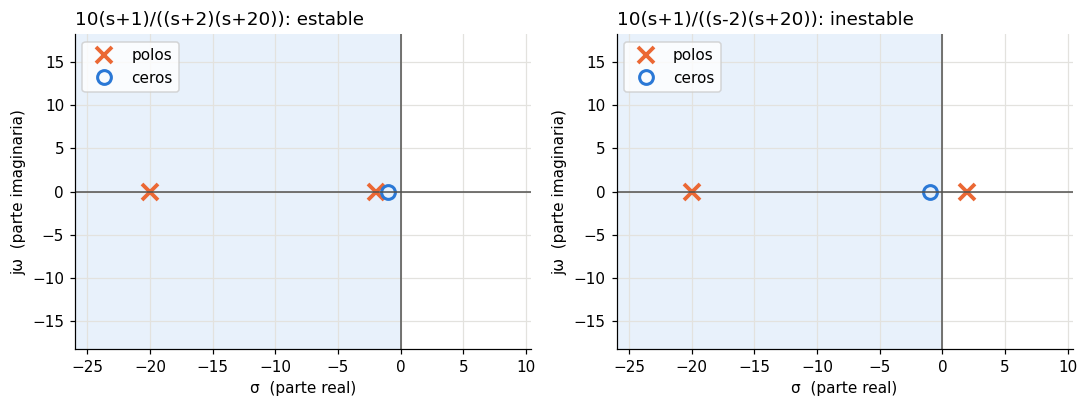

In [6]:
def plano_s(P, ax=None, titulo=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    lim = 1.3 * max([1] + [abs(z) for z in np.r_[P.polos, P.ceros]])
    ax.axvspan(-lim, 0, color="#e8f1fb", zorder=0)          # semiplano izquierdo = estable
    ax.plot(P.polos.real, P.polos.imag, "x", color=NARANJA, ms=10, mew=2.5, label="polos")
    if len(P.ceros):
        ax.plot(P.ceros.real, P.ceros.imag, "o", mfc="none", color=AZUL, ms=9, mew=2, label="ceros")
    ax.axhline(0, color=GRIS, lw=1); ax.axvline(0, color=GRIS, lw=1)
    ax.set_xlim(-lim, lim * 0.4); ax.set_ylim(-lim * 0.7, lim * 0.7)
    ax.set_xlabel("σ  (parte real)"); ax.set_ylabel("jω  (parte imaginaria)")
    ax.set_title(titulo or ("estable" if P.es_estable() else "INESTABLE"), loc="left")
    ax.legend(loc="upper left"); return ax

P2 = FuncionTransferencia(ceros=[-1], polos=[-2, -20], k=10)      # 10(s+1)/((s+2)(s+20))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
plano_s(P2, ax[0], "10(s+1)/((s+2)(s+20)): estable")
plano_s(FuncionTransferencia([-1], [2, -20], 10), ax[1], "10(s+1)/((s-2)(s+20)): inestable")
plt.tight_layout(); plt.show()

## 5. Qué hace cada polo: la posición decide el comportamiento

Comprobamos con `scipy.signal.step`, que simula la respuesta a un escalón de entrada. Probamos polos reales (rápido/lento), complejos (oscila) y uno en el semiplano derecho (diverge).

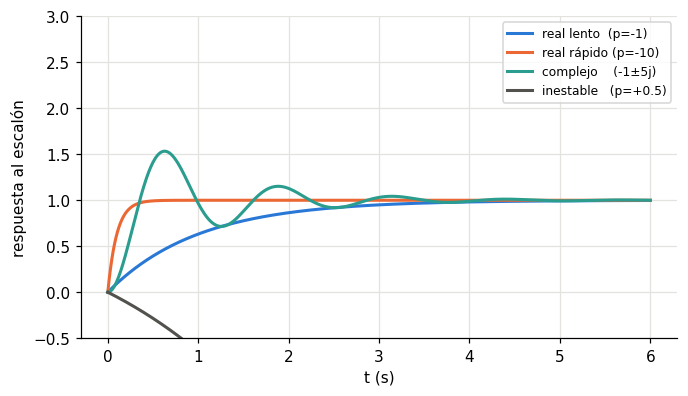

In [7]:
casos = {
    "real lento  (p=-1)":      [-1],
    "real rápido (p=-10)":     [-10],
    "complejo    (-1±5j)":     [-1 + 5j, -1 - 5j],
    "inestable   (p=+0.5)":    [0.5],
}
fig, ax = plt.subplots(figsize=(7, 3.8))
t = np.linspace(0, 6, 800)
for (nombre, polos), col in zip(casos.items(), [AZUL, NARANJA, "#2a9d8f", GRIS]):
    den = np.poly(polos).real
    # escalamos el numerador para que la ganancia en continua sea 1 (cuando existe)
    gain = den[-1] if abs(den[-1]) > 1e-9 else 1.0
    _, y = signal.step(signal.TransferFunction([gain], den), T=t)
    ax.plot(t, np.clip(y, -3, 3), color=col, lw=2, label=nombre)
ax.set_ylim(-0.5, 3); ax.set_xlabel("t (s)"); ax.set_ylabel("respuesta al escalón"); ax.legend(fontsize=8)
plt.show()

- **Más a la izquierda** ⇒ más rápido.
- **Con parte imaginaria** ⇒ oscila.
- **A la derecha del eje imaginario** ⇒ crece sin límite.

## 6. Evaluar $P(s)$ en $s=j\omega$

La pregunta clave del curso: *¿qué hace el sistema con una senoidal de frecuencia $\omega$?* La respuesta está en $P(j\omega)$, que es un **complejo**: su magnitud es la amplificación y su ángulo, el desfase.

Cada factor $(s-p)$ evaluado en $j\omega$ es la **flecha que va del polo $p$ al punto $j\omega$**. Para $P_2(s)=\dfrac{10(s+1)}{(s+2)(s+20)}$ en $\omega=2$:

In [8]:
w = 2
s = 1j * w
print(f"{'factor':>10} {'magnitud':>10} {'ángulo (°)':>11}")
fact = {"s+1": s + 1, "s+2": s + 2, "s+20": s + 20}
for nombre, f in fact.items():
    print(f"{nombre:>10} {abs(f):>10.3f} {np.degrees(np.angle(f)):>11.2f}")

mag = 10 * abs(fact["s+1"]) / (abs(fact["s+2"]) * abs(fact["s+20"]))
fase = np.degrees(np.angle(fact["s+1"]) - np.angle(fact["s+2"]) - np.angle(fact["s+20"]))
print(f"\nP(j2): magnitud = {mag:.4f} = {20*np.log10(mag):.2f} dB, fase = {fase:.2f}°")
assert np.isclose(P2(2j), mag * np.exp(1j * np.radians(fase)))
print("coincide con la evaluación directa P2(2j) =", np.round(P2(2j), 5))

    factor   magnitud  ángulo (°)
       s+1      2.236       63.43
       s+2      2.828       45.00
      s+20     20.100        5.71

P(j2): magnitud = 0.3933 = -8.11 dB, fase = 12.72°
coincide con la evaluación directa P2(2j) = (0.38366+0.08663j)


**La regla.** Cada **cero** suma su ángulo y multiplica su magnitud; cada **polo** resta su ángulo y divide su magnitud.
Las flechas, dibujadas en el plano $s$:

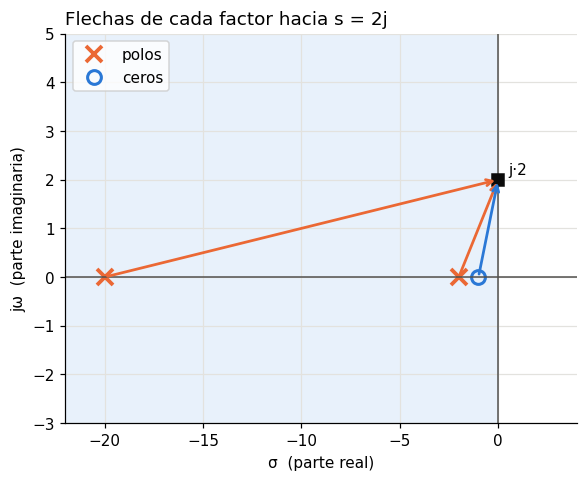

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.6))
plano_s(P2, ax, "Flechas de cada factor hacia s = 2j")
for p, col, nom in [(-2, NARANJA, "polo -2"), (-20, NARANJA, "polo -20")]:
    ax.annotate("", xy=(0, 2), xytext=(p, 0), arrowprops=dict(arrowstyle="->", color=col, lw=1.8))
ax.annotate("", xy=(0, 2), xytext=(-1, 0), arrowprops=dict(arrowstyle="->", color=AZUL, lw=1.8))
ax.plot(0, 2, "s", color=TINTA, ms=8); ax.text(0.5, 2.1, "j·2")
ax.set_xlim(-22, 4); ax.set_ylim(-3, 5)
plt.show()

## 7. ¿Para qué sirve $P(j5)$? Qué hace el sistema con una senoidal

Si entra $u(t)=\sin(\omega t)$, en régimen permanente sale

$$y(t)=|P(j\omega)|\,\sin\big(\omega t+\angle P(j\omega)\big).$$

Lo **verificamos** simulando el sistema completo con `scipy.signal.lsim` y comparando con la predicción de $P(j\omega)$.

|P(j5)| = 0.00465,  ∠P = -54.46°
error máximo entre la simulación y la predicción (t>3): 2.19e-08


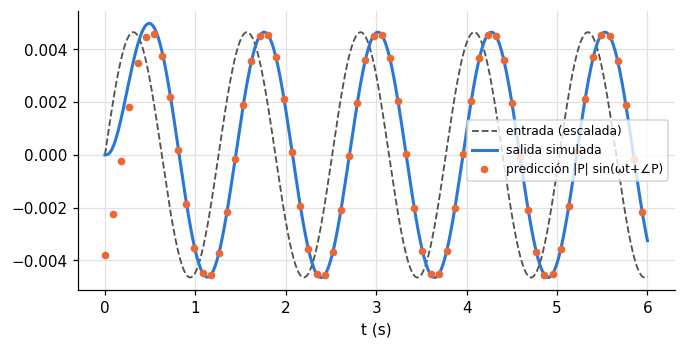

In [10]:
w = 5.0
Pw = P1(1j * w)                                 # planta del paso 1: 1/((s+5)(s+30))
num, den = P1.coeficientes()
t = np.linspace(0, 6, 4000)
u = np.sin(w * t)
_, y, _ = signal.lsim(signal.TransferFunction(num, den), u, t)

pred = abs(Pw) * np.sin(w * t + np.angle(Pw))   # predicción con |P| y ∠P
tail = t > 3                                   # ignoramos el transitorio inicial
print(f"|P(j5)| = {abs(Pw):.5f},  ∠P = {np.degrees(np.angle(Pw)):.2f}°")
print(f"error máximo entre la simulación y la predicción (t>3): {np.max(np.abs(y[tail]-pred[tail])):.2e}")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(t, u * abs(Pw), color=GRIS, lw=1.2, ls="--", label="entrada (escalada)")
ax.plot(t, y, color=AZUL, lw=2, label="salida simulada")
ax.plot(t[::60], pred[::60], "o", color=NARANJA, ms=4, label="predicción |P| sin(ωt+∠P)")
ax.set_xlabel("t (s)"); ax.legend(fontsize=8); plt.show()

La salida es otra senoidal **de la misma frecuencia**, con distinta amplitud y desfasada. Todo el estudio de QFT consiste en saber cuánto cambian esos dos números cuando la planta no se conoce exactamente.

## 8. Un cero hace lo contrario

Un cero **suma** ángulo y **sube** la magnitud. Comparamos $P(s)=\dfrac{1}{(s+2)(s+20)}$ con la misma planta con un cero en $s=-1$:

In [11]:
Psin = FuncionTransferencia([], [-2, -20], k=1)
Pcon = FuncionTransferencia([-1], [-2, -20], k=1)
for w in [0.1, 1, 2, 10, 100]:
    a, b = Psin(1j*w), Pcon(1j*w)
    print(f"w={w:>5}:  sin cero {20*np.log10(abs(a)):7.2f} dB {np.degrees(np.angle(a)):7.2f}°"
          f"   |   con cero {20*np.log10(abs(b)):7.2f} dB {np.degrees(np.angle(b)):7.2f}°")

w=  0.1:  sin cero  -32.05 dB   -3.15°   |   con cero  -32.01 dB    2.56°
w=    1:  sin cero  -33.02 dB  -29.43°   |   con cero  -30.01 dB   15.57°
w=    2:  sin cero  -35.09 dB  -50.71°   |   con cero  -28.11 dB   12.72°
w=   10:  sin cero  -47.16 dB -105.26°   |   con cero  -27.12 dB  -20.97°
w=  100:  sin cero  -80.17 dB -167.54°   |   con cero  -40.17 dB  -78.12°


## 9. Ejercicio del Paso 2

Sea $P(s)=\dfrac{10(s+1)}{(s+2)(s+20)}$.

1. Indica sus polos y ceros y dibújalos.
2. ¿Es estable? Justifícalo.
3. Calcula $P(j2)$: magnitud en dB y fase, **sumando la contribución de cada factor**.
4. Comprueba multiplicando en rectangular.

**Tu turno.** Hemos definido `P2` arriba; usa sus atributos.

In [12]:
# 1) polos y ceros: P2.polos, P2.ceros ; dibuja con plano_s(P2)
# 2) estabilidad: P2.es_estable()
# 3) contribuciones de cada factor en s = 2j (magnitud en dB y fase)
# 4) comprobación rectangular
# escribe aquí tu código

In [13]:
print("polos:", P2.polos.real, "  ceros:", P2.ceros.real, "  estable:", P2.es_estable())
s = 2j
db = lambda z: 20*np.log10(abs(z))
# magnitud en dB = suma de contribuciones (cero suma, polos restan)
mag_db = 20*np.log10(10) + db(s + 1) - db(s + 2) - db(s + 20)
fase = np.degrees(np.angle(s + 1) - np.angle(s + 2) - np.angle(s + 20))
print(f"P(j2): {mag_db:.2f} dB, {fase:.2f}°    (diapositivas: -8.11 dB, 12.72°)")
# rectangular: 10(1+2j)/((2+2j)(20+2j)),  (2+2j)(20+2j) = 36+44j
rect = 10 * (1 + 2j) / ((2 + 2j) * (20 + 2j))
print("rectangular:", np.round(rect, 5), "->", f"{db(rect):.2f} dB, {np.degrees(np.angle(rect)):.2f}°")
assert np.isclose(rect, P2(2j)) and np.isclose(mag_db, db(rect)) and np.isclose(fase, np.degrees(np.angle(rect)))

polos: [ -2. -20.]   ceros: [-1.]   estable: True
P(j2): -8.11 dB, 12.72°    (diapositivas: -8.11 dB, 12.72°)
rectangular: (0.38366+0.08663j) -> -8.11 dB, 12.72°


## 10. Resumen

- Un sistema se describe por una ecuación diferencial; con Laplace queda $P(s)=N(s)/D(s)$.
- **Polos** = raíces del denominador; **ceros** = raíces del numerador. Estable ⇔ todos los polos con $\mathrm{Re}<0$.
- $P(j\omega)$ es un complejo; cada factor es una flecha del polo/cero al punto $j\omega$. Ceros suman ángulo y multiplican; polos restan y dividen.
- En código: una **clase** con `__call__` convierte la fórmula en un objeto reutilizable; `scipy.signal` sirve para **contrastar** lo que calculas a mano.

**Siguiente:** Paso 3, respuesta en frecuencia: $P(j\omega)$ para todas las $\omega$ y el diagrama de Bode.